# 1)Import Python modules

In [30]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import cv2
import os
import PIL
import pathlib

from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D,Dense,Dropout, Flatten,Activation, BatchNormalization,MaxPooling2D
from tensorflow.keras import datasets, layers, models
from tensorflow.keras.preprocessing.image import load_img
from tensorflow.keras.preprocessing.image import img_to_array

# 2)Load dataset

In [31]:
data_dir = pathlib.Path("C:/Users/dpava/Downloads/catsvsdogs/PetImages")
print(data_dir)
list(data_dir.glob('*/*.jpg'))[:5]

C:\Users\dpava\Downloads\catsvsdogs\PetImages


[WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/0.jpg'),
 WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/1.jpg'),
 WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/10.jpg'),
 WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/100.jpg'),
 WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/1000.jpg')]

[WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/0.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/1.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/10.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/100.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/1000.jpg')]


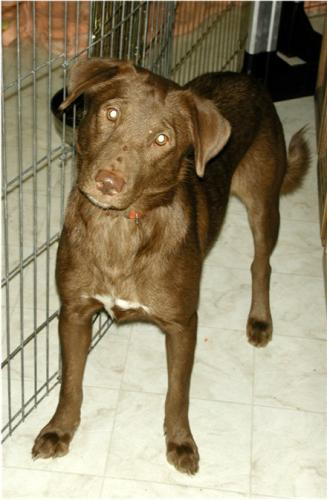

In [32]:
dogs = list(data_dir.glob('Dog/*'))
print(dogs[:5])
PIL.Image.open(str(dogs[1]))

[WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/0.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/1.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/10.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/100.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/1000.jpg')]


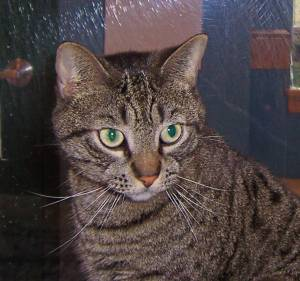

In [33]:
cats = list(data_dir.glob('Cat/*'))
print(cats[:5])
PIL.Image.open(str(cats[1]))

# 3)Read Pets images from disk into numpy array using opencv

In [34]:
image_count = len(list(data_dir.glob('*/*.jpg')))
print(image_count)
pet_images_dict = {
    'cats': list(data_dir.glob('Cat/*')),
    'dogs': list(data_dir.glob('Dog/*')),
}

pet_labels_dict = {
    'cats': 0,
    'dogs': 1,
}

print(pet_images_dict['dogs'][:5])
print(pet_images_dict['cats'][:5])

25000
[WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/0.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/1.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/10.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/100.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Dog/1000.jpg')]
[WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/0.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/1.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/10.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/100.jpg'), WindowsPath('C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/1000.jpg')]


In [35]:
IMAGE_WIDTH=128
IMAGE_HEIGHT=128
X, Y = [], []
for pet_name, images in pet_images_dict.items():
    print(pet_name)
    for image in images:
        img = cv2.imread(str(image))
        if isinstance(img,type(None)): 
            #print('image not found')
            continue
            
        elif ((img.shape[0] >= IMAGE_HEIGHT) and  (img.shape[1] >=IMAGE_WIDTH)):
            resized_img = cv2.resize(img,(IMAGE_WIDTH,IMAGE_HEIGHT))
            X.append(resized_img)
            Y.append(pet_labels_dict[pet_name])
        else:
            #print("Invalid Image")
            continue

cats
dogs


In [36]:
X = np.array(X)
Y = np.array(Y)

# 4)Train Test split

In [37]:
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, random_state=0)
print(len(X_train),len(Y_train))
print(len(X_test),len(Y_test))

print(X_train.shape,Y_train.shape)
print(X_test.shape,Y_test.shape)

18327 18327
6110 6110
(18327, 128, 128, 3) (18327,)
(6110, 128, 128, 3) (6110,)


# 5)Build convolutional neural network and train it

In [38]:
IMAGE_CHANNELS=3
model = Sequential([

Conv2D(32, (3, 3), activation='relu', input_shape=(IMAGE_WIDTH, IMAGE_HEIGHT, IMAGE_CHANNELS)),
BatchNormalization(),
MaxPooling2D(pool_size=(2, 2)),
Dropout(0.25),

Conv2D(64, (3, 3), activation='relu'),
BatchNormalization(),
MaxPooling2D(pool_size=(2, 2)),
Dropout(0.25),

Conv2D(128, (3, 3), activation='relu'),
BatchNormalization(),
MaxPooling2D(pool_size=(2, 2)),
Dropout(0.25),

Flatten(),
Dense(512, activation='relu'),
BatchNormalization(),
Dropout(0.5),
Dense(1, activation='sigmoid'), # 2 because we have cat and dog classes
])

model.compile(loss='binary_crossentropy', optimizer='adam', metrics=['accuracy'])

model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 126, 126, 32)      896       
                                                                 
 batch_normalization (BatchN  (None, 126, 126, 32)     128       
 ormalization)                                                   
                                                                 
 max_pooling2d (MaxPooling2D  (None, 63, 63, 32)       0         
 )                                                               
                                                                 
 dropout (Dropout)           (None, 63, 63, 32)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 61, 61, 64)        18496     
                                                                 
 batch_normalization_1 (Batc  (None, 61, 61, 64)       2

In [39]:
history=model.fit(X_train, Y_train, epochs=10)

Epoch 1/10
573/573 [==============================] - 288s 498ms/step - loss: 0.6734 - accuracy: 0.6661
Epoch 2/10
573/573 [==============================] - 284s 496ms/step - loss: 0.4859 - accuracy: 0.7694
Epoch 3/10
573/573 [==============================] - 295s 514ms/step - loss: 0.4263 - accuracy: 0.8040
Epoch 4/10
573/573 [==============================] - 302s 526ms/step - loss: 0.3962 - accuracy: 0.8202
Epoch 5/10
573/573 [==============================] - 295s 515ms/step - loss: 0.3380 - accuracy: 0.8534
Epoch 6/10
573/573 [==============================] - 284s 496ms/step - loss: 0.3039 - accuracy: 0.8678
Epoch 7/10
573/573 [==============================] - 296s 516ms/step - loss: 0.2702 - accuracy: 0.8861
Epoch 8/10
573/573 [==============================] - 283s 494ms/step - loss: 0.2283 - accuracy: 0.9077
Epoch 9/10
573/573 [==============================] - 283s 493ms/step - loss: 0.1906 - accuracy: 0.9238
Epoch 10/10
573/573 [==============================] - 1524s 3s/

In [40]:
model.evaluate(X_test,Y_test)

191/191 [==============================] - 15s 79ms/step - loss: 0.5758 - accuracy: 0.7810


[0.5757800340652466, 0.7810147404670715]

In [41]:
from sklearn.metrics import confusion_matrix , classification_report
y_pred = model.predict(X_test)
y_pred_classes = [0 if element < 0.5 else 1 for element in y_pred]

print("Classification Report: \n", classification_report(Y_test, y_pred_classes))

191/191 [==============================] - 16s 81ms/step
Classification Report: 
               precision    recall  f1-score   support

           0       0.91      0.63      0.74      3066
           1       0.71      0.94      0.81      3044

    accuracy                           0.78      6110
   macro avg       0.81      0.78      0.78      6110
weighted avg       0.81      0.78      0.78      6110



# 6)Evaluate the model

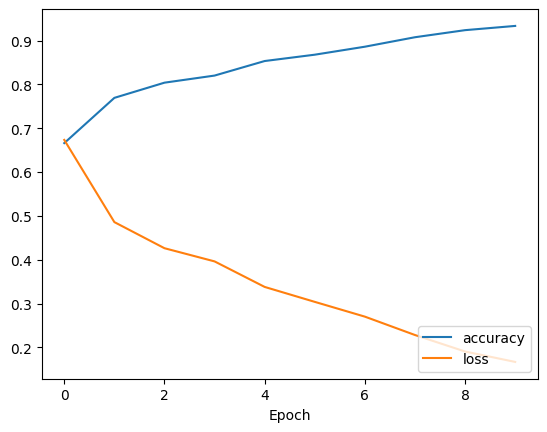

In [42]:
plt.plot(history.history['accuracy'], label='accuracy')
plt.plot(history.history['loss'], label = 'loss')
plt.xlabel('Epoch')
plt.legend(loc='lower right')
plt.show()

# 7)Predict

1/1 [==============================] - 0s 36ms/step
[[0.01386596]]
class: 0 name= cat


C:\Users\dpava\AppData\Local\Temp\ipykernel_29616\1050350802.py:3: DeprecationWarning: ANTIALIAS is deprecated and will be removed in Pillow 10 (2023-07-01). Use LANCZOS or Resampling.LANCZOS instead.
  fileImage = Image.open("C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/6234.jpg").convert("RGB").resize([IMAGE_WIDTH,IMAGE_HEIGHT],Image.ANTIALIAS)


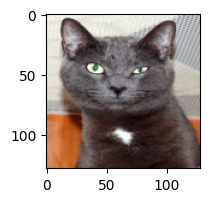

In [43]:
classes = ["cat","dog"]
from PIL import Image
fileImage = Image.open("C:/Users/dpava/Downloads/catsvsdogs/PetImages/Cat/6234.jpg").convert("RGB").resize([IMAGE_WIDTH,IMAGE_HEIGHT],Image.ANTIALIAS)
image = np.array(fileImage)
myimage = image.reshape(1, IMAGE_WIDTH,IMAGE_HEIGHT,3)
# prepare pixel data
#myimage = myimage.astype('float32')
#myimage = myimage/255.
plt.figure(figsize = (4,2))
plt.imshow(image)

my_predicted_image = model.predict(myimage)
print(my_predicted_image)
if (my_predicted_image < 0.40):
    y_class=0 
else:
    y_class=1
print("class:",y_class,"name=",classes[y_class])